In [1]:
import networkx as nx
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd
import openpyxl

In [127]:
%pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]━━ 1/2 [openpyxl]
Note: you may need to restart the kernel to use updated packages.


In [36]:
## Import data from text file and import list of "essential" proteins

raw = nx.read_weighted_edgelist("protein.links.clean.txt",comments="#",nodetype=str)
raw_phys = nx.read_weighted_edgelist("protein.physical.links.clean.txt",comments="#",nodetype=str)

essential = pd.read_csv("Data - List of essential proteins of saccharomyces cerevisiae.csv", header=None)
ess_prot = set(essential.iloc[:,1])

ess_graph = raw.subgraph(ess_prot).copy()
## ----------------------------------------------------------------

In [37]:
target = "YMR161W"
confidence = 700  ## Minimum edge strength (anything below ignored)

graph = raw.copy()
physical = raw_phys.copy()
non_essential = set(graph.nodes) - ess_prot
non_ess_graph = graph.subgraph(non_essential).copy()

# removes any edges below the confidence score
for e in graph.edges:
    weight = list(graph.get_edge_data(e[0],e[1]).values())
    if(weight[0] <= confidence):
        graph.remove_edge(e[0],e[1])

# Identifies largest connected component and ignores any disconnected nodes
largest = max(nx.connected_components(graph), key=len)
graph = graph.subgraph(largest).copy()


## Create a copy with the target node removed for analysis
if target in graph:
    edit = graph.copy()
    edit.remove_node(target)
else:
    print(f"{target} not included in network") 


# Repeat for Physical links data -------------------------------------------------------------------
# --------------------------------------------------------------------------------------------------

# removes any edges below the confidence score
for e in physical.edges:
    weight = list(physical.get_edge_data(e[0],e[1]).values())
    if(weight[0] <= confidence):
        physical.remove_edge(e[0],e[1])

# Identifies largest connected component and ignores any disconnected nodes
largest = max(nx.connected_components(physical), key=len)
physical = physical.subgraph(largest).copy()

## Create a copy with the target node removed for analysis
if target in physical:
    phys_edit = physical.copy()
    phys_edit.remove_node(target)
else:
    print(f"{target} not included in physical network") 

YMR161W not included in physical network


In [38]:
## Create set of nodes local to target node

# note distance of 4: 4586, 3: 2437, 2: 254, ___ (5519 total)
distance = 2

local_nodes = set(nx.single_source_shortest_path_length(graph, target, cutoff=distance).keys())


print(len(local_nodes))
print(len(graph))

389
5697


In [42]:
print(nx.shortest_path("YMR161W" in graph, "YJL034C" in graph))


TypeError: argument of type 'bool' is not a container or iterable

In [10]:
# Compare with and without HLJ1

control = nx.betweenness_centrality(graph)
measure = nx.betweenness_centrality(edit)



In [11]:
difference = {node: measure[node] - control[node] for node in edit.nodes}

relative = {
    node: difference[node] / measure[node]
    for node in edit.nodes
    if measure[node] != 0
}

top_20_rel = sorted(relative.items(), key=lambda x: -x[1])[:20]

not_local_rel = [(node, diff) for node, diff in top_20_rel if node not in local_nodes]

for node, diff in not_local_rel:
    print(f"{node}: {diff:+.5f}")

for node in top_20_rel:
    print(node)



YHR003C: +0.00461
YJR117W: +0.00413
YDL049C: +0.00231
YHR110W: +0.00218
YDR461W: +0.00149
YLR271W: +0.00133
YGL091C: +0.00128
YFR042W: +0.00111
('YJL162C', 0.014214060803924226)
('YNL077W', 0.009009298510593343)
('YFL016C', 0.006966136062129745)
('YPL096W', 0.006933052858816145)
('YHR003C', 0.004614738369542549)
('YJR117W', 0.004127007415368159)
('YLR090W', 0.002922119155948297)
('YNL064C', 0.002835012692083959)
('YBR169C', 0.0026274215501780034)
('YMR214W', 0.0025931580133569)
('YDL049C', 0.0023081910083411076)
('YHR110W', 0.0021764835769332563)
('YER048C', 0.0016288493678891002)
('YDR461W', 0.0014908435689055426)
('YIR004W', 0.001471058104232903)
('YLR271W', 0.0013330775367292823)
('YGL091C', 0.001283112034728621)
('YNL007C', 0.0012671400910305214)
('YKL117W', 0.0012101478850924784)
('YFR042W', 0.001108359422784893)


Skipped 254 nodes with no score. Re-run the Betweenness cell so it matches the current graph.


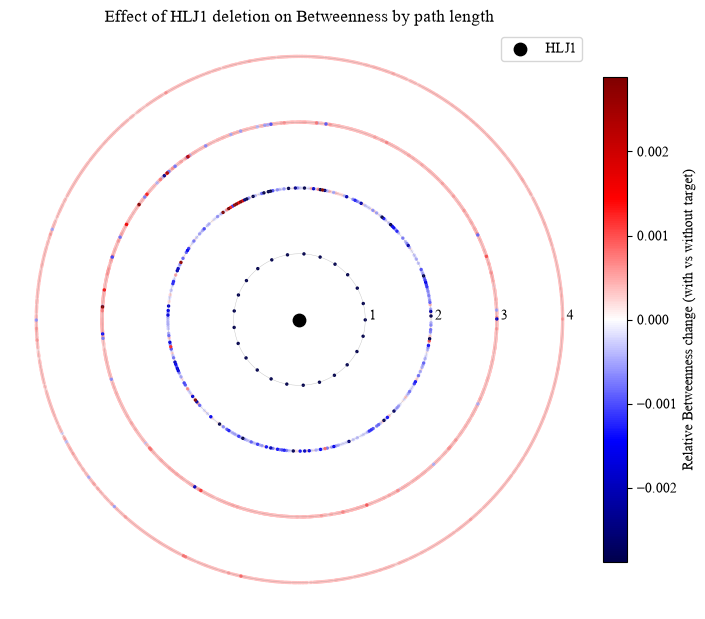

In [28]:
max_dist = 4   # keep nodes with path length < 6

dist = nx.single_source_shortest_path_length(graph, target, cutoff=max_dist)

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"]

# group nodes by distance, keeping only nodes that have a score
rings = {}
missing = 0
for node, d in dist.items():
    if node == target:
        continue
    if node in relative:
        rings.setdefault(d, []).append(node)
    else:
        missing += 1

if missing:
    print(f"Skipped {missing} nodes with no score. Re-run the Betweenness cell so it matches the current graph.")

xs, ys, cs = [], [], []
for d, nodes in rings.items():
    angles = np.linspace(0, 2*np.pi, len(nodes), endpoint=False) + d
    xs += list(d*np.cos(angles))
    ys += list(d*np.sin(angles))
    cs += [relative[n] for n in nodes]

xs, ys, cs = np.array(xs), np.array(ys), np.array(cs)

# clip the colour scale so a few extreme nodes don't wash out everything else
lim = np.percentile(np.abs(cs), 99)

# draw the strongest effects last so they sit on top
order = np.argsort(np.abs(cs))

fig, ax = plt.subplots(figsize=(9, 9))
sc = ax.scatter(xs[order], ys[order], c=cs[order], cmap="seismic",
                vmin=-lim, vmax=lim, s=6, linewidths=0)

# target in the centre
ax.scatter([0], [0], c="black", s=80, marker="o", zorder=5, label="HLJ1")

# faint guide circles
t = np.linspace(0, 2*np.pi, 300)
for d in rings:
    ax.plot(d*np.cos(t), d*np.sin(t), color="grey", lw=0.3, alpha=0.5)
    ax.text(d, 0, f" {d}", fontsize=10, color="black")

plt.colorbar(sc, ax=ax, shrink=0.7, aspect=20, pad=0.02,
             label="Relative Betweenness change (with vs without target)",
             extend="neither")
ax.set_aspect("equal")
ax.axis("off")
ax.legend(loc="upper right")
ax.set_title(f"Effect of HLJ1 deletion on Betweenness by path length")


fig.savefig("betweenness_rings.pdf", bbox_inches="tight")
fig.savefig("betweenness_rings.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:
## Non-Essential nodes test

non_essential = set(graph.nodes) - ess_prot
non_ess_graph = graph.subgraph(non_essential.copy())

In [34]:
dist = nx.single_source_shortest_path_length(graph, target)

df = pd.DataFrame({
    "relative": pd.Series(relative),
    "distance": pd.Series(dist)
})

df = df.drop(index=target, errors="ignore")   # target has no score
df["essential"] = df.index.isin(ess_prot)
df["local"] = df.index.isin(local_nodes)

# keep only finite scores
df = df[np.isfinite(df["relative"])]

top = (df[~df["essential"] & (df["distance"] > 1)]
         .assign(abs_rel=lambda d: d["relative"])
         .sort_values("abs_rel", ascending=False)
         .head(20)
         .drop(columns="abs_rel"))

print(top)

           relative  distance  essential  local
YJL162C    0.014214         2      False   True
YNL077W    0.009009         2      False   True
YFL016C    0.006966         2      False   True
YPL096W    0.006933         2      False   True
YHR003C    0.004615         3      False  False
YJR117W    0.004127         3      False  False
YLR090W    0.002922         2      False   True
YNL064C    0.002835         2      False   True
YBR169C    0.002627         2      False   True
YMR214W    0.002593         2      False   True
YDL049C    0.002308         3      False  False
YHR110W    0.002176         3      False  False
YER048C    0.001629         2      False   True
YDR461W    0.001491         3      False  False
YLR271W    0.001333         3      False  False
YKL117W    0.001210         2      False   True
YOL038C-A  0.001067         5      False  False
YGR143W    0.000985         3      False  False
YOR188W    0.000975         3      False  False
YML013W    0.000964         2      False

In [16]:
dist = nx.single_source_shortest_path_length(graph, target)

df = pd.DataFrame({
    "relative": pd.Series(relative),
    "distance": pd.Series(dist)
})

df = df.drop(index=target, errors="ignore")
df["essential"] = df.index.isin(ess_prot)
df["local"] = df.index.isin(local_nodes)
df = df[np.isfinite(df["relative"])]

out = df.reset_index().rename(columns={"index": "protein"})

out_abs = out.sort_values("relative", key=abs, ascending=False)
out_desc = out.sort_values("relative", ascending=False)

with pd.ExcelWriter("YMR161W_betweenness_change.xlsx") as writer:
    out_abs.to_excel(writer, sheet_name="abs_descending", index=False)
    out_desc.to_excel(writer, sheet_name="value_descending", index=False)

In [33]:
non_essential = set(edit.nodes) - ess_prot

top_20 = sorted(
    ((node, relative[node]) for node in non_essential if np.isfinite(relative[node])),
    key=lambda x: -abs(x[1])
)[:20]

not_local = [(node, diff) for node, diff in top_20 if node not in local_nodes]

for node, diff in not_local:
    print(f"{node}: {diff:+.5f}")

KeyError: 'YBL039C-A'

In [29]:
print(graph.number_of_nodes())
print(graph.number_of_edges())

5697
103764
